In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.1
d = 0.6
alpha = 0.3
bound = 1 / (1 - d)

# Single Run

In [4]:
def make_fixed_Q(q00: float, q01: float, q10: float, q11: float) -> np.ndarray:
    """
    Construct a 2x2 Q matrix from explicit scalar values.
    Returns a numpy array: [[q00, q01], [q10, q11]]
    """
    Q = np.array([[q00, q01],
                  [q10, q11]], dtype=float)
    return Q

# ---------------------------
# Save / load named sets in JSON
# ---------------------------
def save_fixed_Q_named(name: str, Q: np.ndarray, file_path: str = "fixed_initialization.json") -> None:
    """
    Save a named Q (2x2 numpy array) into a JSON file under `name`.
    The JSON structure is { "<name>": {"Q00":..., "Q01":..., "Q10":..., "Q11":...}, ... }
    """
    if Q.shape != (2, 2):
        raise ValueError("Q must be a 2x2 array.")
    entry = {"Q00": float(Q[0,0]), "Q01": float(Q[0,1]), "Q10": float(Q[1,0]), "Q11": float(Q[1,1])}

    try:
        with open(file_path, "r") as f:
            all_data = json.load(f)
    except (FileNotFoundError, json.JSONDecodeError):
        all_data = {}

    all_data[name] = entry
    with open(file_path, "w") as f:
        json.dump(all_data, f, indent=4)
    print(f"Saved Q under name '{name}' to {file_path}")

def load_fixed_Q_named(name: str, file_path: str = "fixed_initialization.json") -> np.ndarray:
    """
    Load a named Q from JSON and return as 2x2 numpy array.
    """
    with open(file_path, "r") as f:
        all_data = json.load(f)

    if name not in all_data:
        raise KeyError(f"Name '{name}' not found in {file_path}. Available keys: {list(all_data.keys())}")
    d = all_data[name]
    required = {"Q00","Q01","Q10","Q11"}
    if not required.issubset(d.keys()):
        raise ValueError(f"Saved entry '{name}' missing keys: {required - set(d.keys())}")
    return make_fixed_Q(d["Q00"], d["Q01"], d["Q10"], d["Q11"])

In [ ]:
algo = Algorithm(
        e=epsilon, lambda_val=0, alpha=alpha, delta=d,
        init_mode='fixed', tolerance=1e-10000, 
        M=int(50), strategy1='AC', strategy2='AC', verbose=False
    )
q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()  
exp = np.random.randint(0, 50)
q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]  

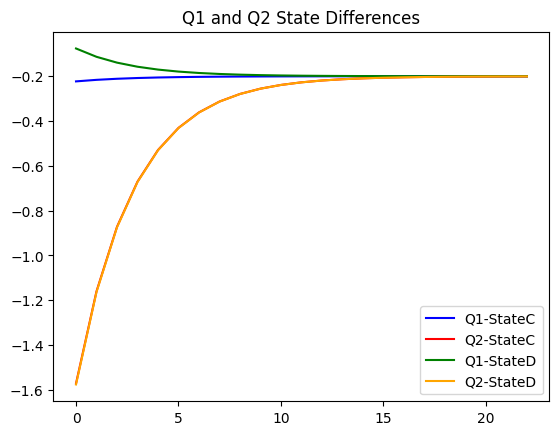

In [9]:
internal_debug = True
if internal_debug:
    q1['StateC'] = q1['Q1'] - q1['Q3']
    q1['StateD'] = q1['Q2'] - q1['Q4']
    q2['StateC'] = q2['Q1'] - q2['Q3']
    q2['StateD'] = q2['Q2'] - q2['Q4']
    x = q1['StateC'].values
    y = q2['StateC'].values
    z = q1['StateD'].values
    w = q2['StateD'].values
    pd.Series(x).plot(title='Q1-StateC', color='blue')
    pd.Series(y).plot(title='Q2-StateC', color='red')
    pd.Series(z).plot(title='Q1-StateD', color='green')
    pd.Series(w).plot(title='Q2-StateD', color='orange')
    plt.title('Q1 and Q2 State Differences')
    plt.legend(['Q1-StateC', 'Q2-StateC', 'Q1-StateD', 'Q2-StateD'])


In [10]:
#q1.join(q2, rsuffix='_q2', lsuffix='_q1')


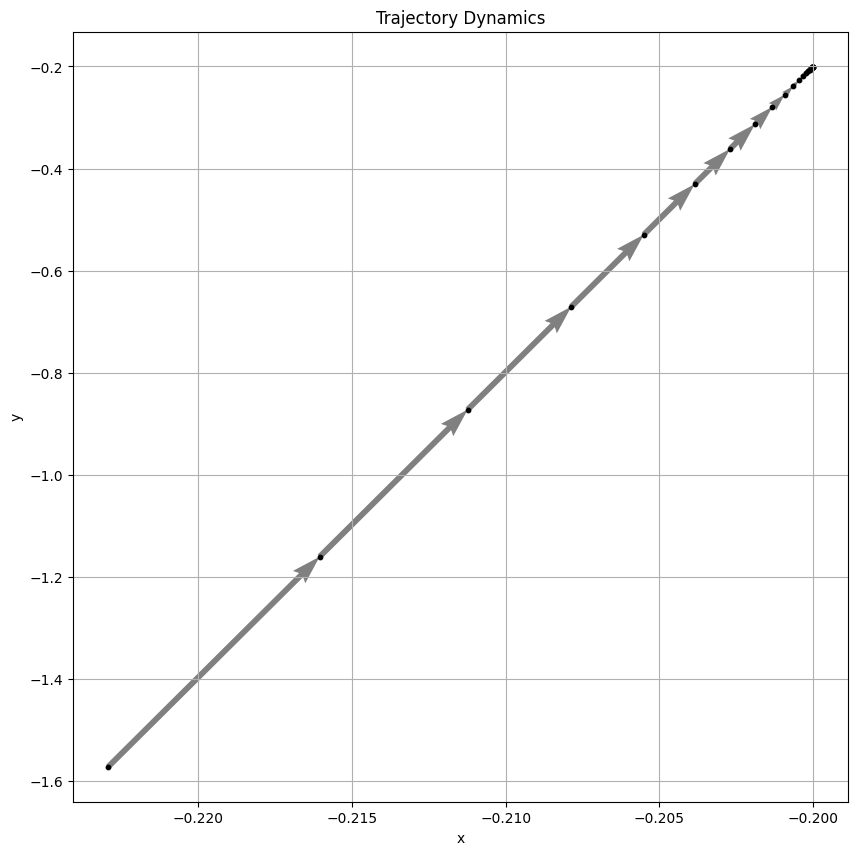

In [11]:
trajectory_dynamics_plot(x, y)

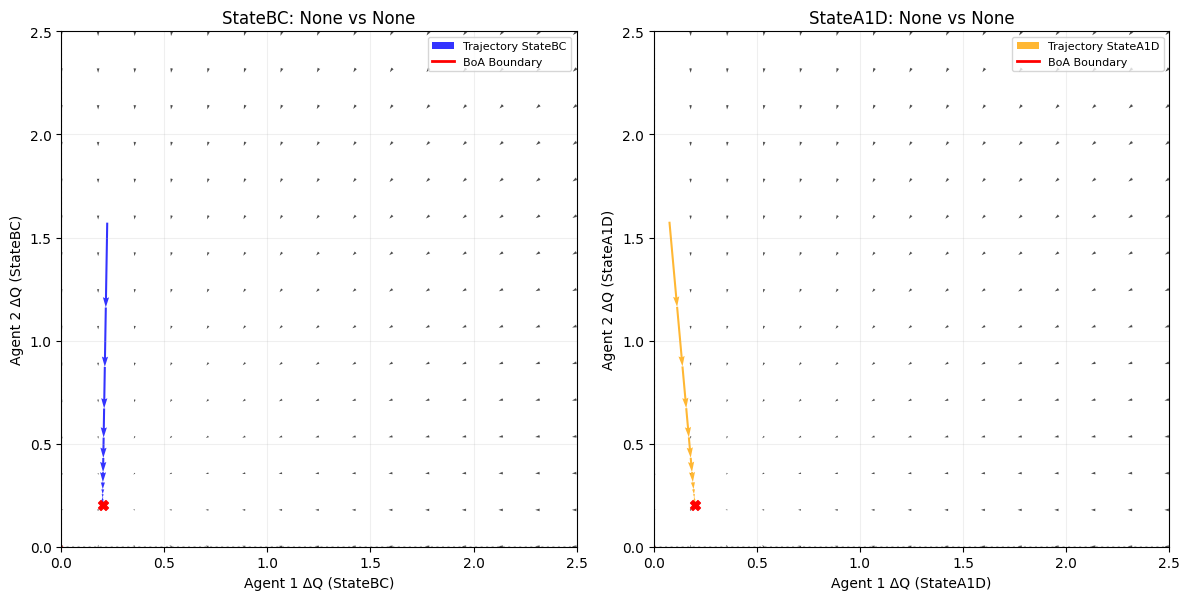

In [12]:
plotter = VectorFieldAutomatic(
        q1=q1, q2=q2,
        t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
        func1=func1,
        func2=func2,
        alpha=alpha,
        show_trajectory=True,
        show_basin=True
    )
plotter.plot()

# CASE BY CASE STUDY

In [11]:
import numpy as np

def trim_q_by_strategy(q1, q2, s1, s2):
    """
    Trim q1 and q2 sequences based on their respective initial strategy orderings.
    Both sequences are cut to the same length, determined by when *either* violates
    its initial ordering — whichever lasts longer determines the trim point.
    
    Parameters
    ----------
    q1, q2 : pd.DataFrame or np.ndarray
        Time × features (Q-values). Must have same length along time axis.
    s1, s2 : str
        Strategies for q1 and q2, each one of {"AD","GT","AGT","AC"}.
        
    Returns
    -------
    q1_trimmed, q2_trimmed : same type as input
        Trimmed sequences up to the last timestep where both maintain initial ordering.
    """
    
    # Convert to numpy if DataFrames
    q1_arr = q1.values if hasattr(q1, "values") else np.asarray(q1)
    q2_arr = q2.values if hasattr(q2, "values") else np.asarray(q2)
    
    def ordering_sign(Q, strategy):
        """
        Compute sign of (defect - coop) according to strategy from a 2x2 Q-matrix or row pair.
        Positive sign → defect > coop, Negative → coop > defect.
        """
        delta = Q[1] - Q[0]
        if strategy in ["GT", "AC"]:
            delta = -delta
        return np.sign(delta)
    
    def valid_length(Q, strategy):
        """Return how long ordering stays consistent with the initial."""
        # Use first two timesteps as reference
        ref_sign = ordering_sign(Q[:2], strategy)
        last_valid_idx = 1
        for t in range(1, Q.shape[0]):
            cur_sign = ordering_sign(Q[t-1:t+1], strategy)
            if np.all(cur_sign == ref_sign):
                last_valid_idx = t
            else:
                break
        return last_valid_idx + 1  # inclusive index
    
    len1 = valid_length(q1_arr, s1)
    len2 = valid_length(q2_arr, s2)
    
    # Cut based on whichever lasts longer
    cut_len = min(len1, len2) 
    
    if hasattr(q1, "iloc"):
        return q1.iloc[:cut_len], q2.iloc[:cut_len]
    else:
        return q1_arr[:cut_len], q2_arr[:cut_len]


Using seed: 535321783
Running pair: (AC, AC)


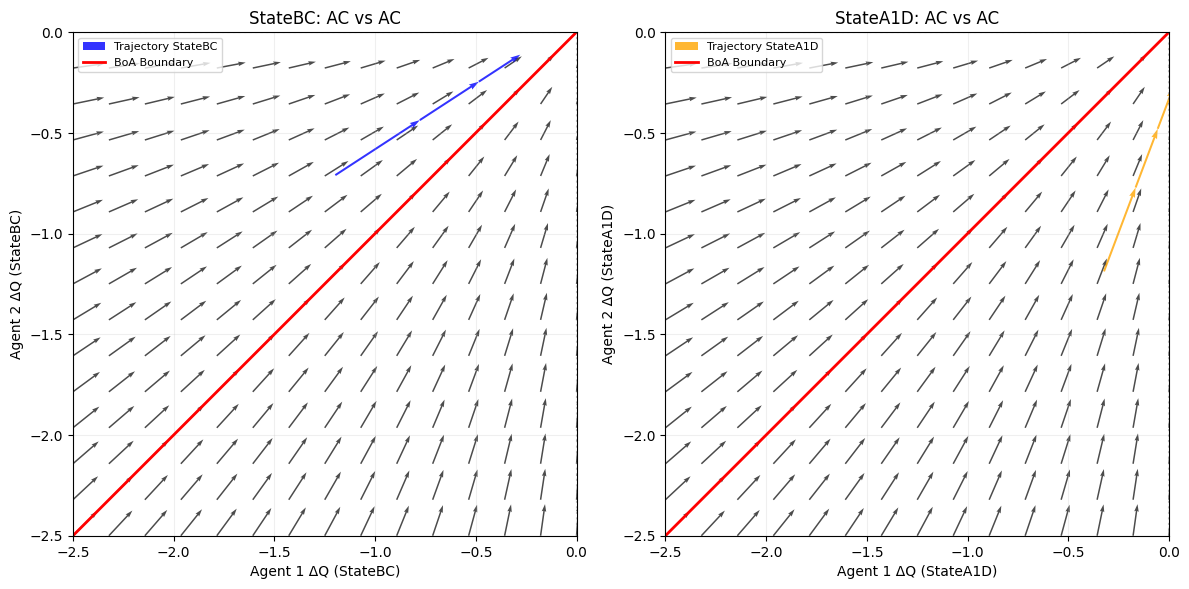

In [28]:
# Strategy pairs
strategy_pairs = [
    #("AD","AD"), ("AD","GT"), ("AD","AGT"), ("AD","AC"),
    #("GT","AD"), ("GT","GT"), ("GT","AGT"), ("GT","AC"),
    #("AGT","AD"), ("AGT","GT"), ("AGT","AGT"), ("AGT","AC"),
    #("AC","AD"), ("AC","GT"), ("AC","AGT"), 
    ("AC","AC")
]
stop_when_cross = True
# Map opponent strategy to function
func_map = {
    "AD": QvaluesADvsAD,
    "GT": QvaluesGTvsGT,
    "AGT": QvaluesADvsAGT,
    "AC": QvaluesADvsAC
}
randomseeds = np.random.randint(1, 1020131031, size=1)  # 5 is exclusive

for seed in randomseeds:
    np.random.seed(seed)
    print(f"Using seed: {seed}")
    for s1, s2 in strategy_pairs:
        print(f"Running pair: ({s1}, {s2})")

        # Initialize algorithm with fixed strategy pair
        algo = Algorithm(
            e=epsilon, lambda_val=0, alpha=alpha, delta=d,
            init_mode='fixed', tolerance=1e-10000, 
            M=50, strategy1=s1, strategy2=s2, verbose=False
        )

        # Run the algorithm
        q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()

        # Pick a sample
        exp = np.random.randint(0, 50)
        q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
        q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]
        if stop_when_cross:
            q1, q2 = trim_q_by_strategy(q1, q2, s1, s2)
        func1 = func_map[s2]  # x-component uses opponent strategy s2
        func2 = func_map[s1]  # y-component uses same opponent strategy
        #check if the ordering changes here input (q1, q2, s1, s2)
        # Plot vector field with strategy information
        plotter = VectorFieldAutomatic(
            q1=q1, q2=q2,
            t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
            func1=func1,
            func2=func2,
            strategy1=s1,    # Add strategy1
            strategy2=s2,    # Add strategy2
            alpha=alpha,
            density=15,
            show_trajectory=True,
            show_basin=True
        )
        
                    
                    
        plotter.plot(show_all_quadrants=False)
        
    





In [4]:
#ORGANIZE THE DESCRIPTION:
#BBoA = BoundaryBasinOfAttraction
#first you plot ADAD and then GTGT #equilibria
#plot two side of bboa
#the case in which just the bboa decide in which equilibria we will go
#AD-GT: if you start below the bboa you will definetely go to GT, if you start on top of the bboa you will go to AD (top-right quadrant)
# target remains in the top right quadrant


#AD - AGT: we don't have the bboa, in any initialization will go to ADAD, there is nothing different can happen, mention ADAD plot.
#AD - AC: the only place top boundary but there are
# two options (which axes we cross first in A1D state or BC state): A1D first) so agent2 is switching from cooperating to defecting in the A1D state, 
# but it still cooperating in the BC state, so agent 2 is switching to play GT, and player1 is still playing AD, so we need to look at AD-GT case,
# so now the moment in which cross the axes on the left hand side determines looking at the point on the right hand side whether you go to AD or GT.
#2 option) we are crossing first in the BC state, so we go to AD-AGT, and we definetely go to ADAD as discussed above

#AC-AC: 
#cross A1D (right of the boundary): 
#cross BC  (right of the boundary):
#cross A1D (left of the boundary ):
#cross BC  (left of the boundary first): cross on the right hadn boundary, they will end up in AGT-AC, we come into this plot from the left
# ACAC can lead to AGT-AC, GT-AC, AC-AGT, AC-GT, and from those situation where can I go?




In [5]:

#next steps:
# a plot for each side of the BBoA in the quadrants where the BBoA is plotted

In [6]:
x_bounds

NameError: name 'x_bounds' is not defined